# Project 5: Adult Census Income Prediction

## Step 1: Dataset Loading and Initial Inspection

**Objective:** Understand the dataset structure, rows, columns, data types, and missing values before starting data preprocessing or model training.

In [1]:
# ===== STEP 1: Libraries import karo =====
import pandas as pd  # data handle karne ke liye
import numpy as np  # numbers ke kaam ke liye
import matplotlib.pyplot as plt  # graph banane ke liye
import seaborn as sns  # sundar graph banane ke liye
from sklearn.model_selection import train_test_split  # data ko train aur test me todne ke liye
from sklearn.preprocessing import StandardScaler  # data ko scale karne ke liye
from sklearn.linear_model import LogisticRegression  # model 1
from sklearn.tree import DecisionTreeClassifier  # model 2
from sklearn.ensemble import RandomForestClassifier  # model 3
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix  # score nikalne ke liye

In [2]:
df = pd.read_csv('adult.csv')
print(df)

       age workclass  fnlwgt     education  education.num      marital.status  \
0       90         ?   77053       HS-grad              9             Widowed   
1       82   Private  132870       HS-grad              9             Widowed   
2       66         ?  186061  Some-college             10             Widowed   
3       54   Private  140359       7th-8th              4            Divorced   
4       41   Private  264663  Some-college             10           Separated   
...    ...       ...     ...           ...            ...                 ...   
32556   22   Private  310152  Some-college             10       Never-married   
32557   27   Private  257302    Assoc-acdm             12  Married-civ-spouse   
32558   40   Private  154374       HS-grad              9  Married-civ-spouse   
32559   58   Private  151910       HS-grad              9             Widowed   
32560   22   Private  201490       HS-grad              9       Never-married   

              occupation   

In [3]:
df.shape

(32561, 15)

In [4]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [5]:
df.info()     # null values are not present

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [6]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


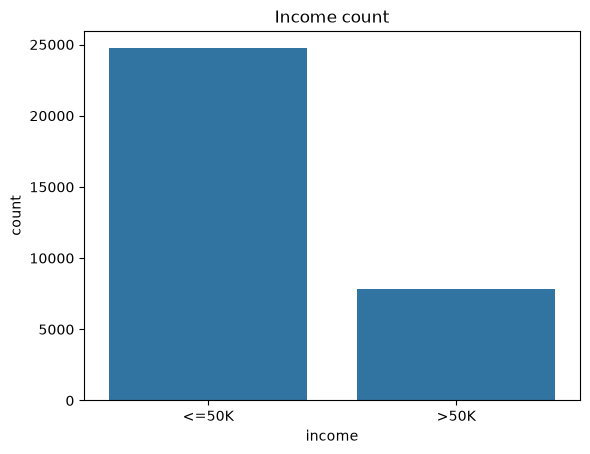

In [7]:
sns.countplot(x = 'income' ,data = df)
plt.title('Income count')
plt.show()

Cleaning

In [8]:
# ===== STEP 5: Data saaf karo =====
df = df.replace("?", np.nan)  # '?' matlab missing value, isliye NaN bana do
print(df.isnull().sum())  # har column me kitni missing values hain
df = df.dropna()  # missing values wali rows hata do
df = df.drop_duplicates()  # duplicate rows hata do
df = df.drop(["fnlwgt", "education"], axis=1)  # fnlwgt kaam ka nahi, education aur education.num same hain
print(df.shape)  # cleaning ke baad shape

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64
(30139, 13)


Target to 0 and 1

In [9]:
# ===== STEP 6: Target ko number banao =====
df["income"] = np.where(df["income"] == ">50K", 1, 0)  # 1 = ameer (>50K), 0 = ameer nahi (<=50K)
print(df["income"].value_counts())  # count check karo

income
0    22633
1     7506
Name: count, dtype: int64


Categorical to Numerical

In [10]:
# ===== STEP 7: Text columns ko number me badlo =====
df = pd.get_dummies(df, drop_first=True)  # one-hot encoding, har text column 0/1 columns ban jayega
print(df.shape)  # ab columns kitne ho gaye
df.head()  # data check karo

(30139, 81)


,age,education.num,capital.gain,capital.loss,hours.per.week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native.country_Portugal,native.country_Puerto-Rico,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia
1,82,9,0,4356,18,0,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,54,4,0,3900,40,0,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,41,10,0,3900,40,0,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
5,34,9,0,3770,45,0,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
6,38,6,0,3770,40,0,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False


Cell 8: Split Data

In [11]:
# ===== STEP 8: X, y banao aur train-test split karo =====
X = df.drop("income", axis=1)  # target ke alawa sab columns
y = df["income"]  # target column
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # 80% train, 20% test
print(X_tr.shape, X_te.shape)  # size check karo

(24111, 80) (6028, 80)


Scaling

In [12]:
# ===== STEP 9: Data scale karo (Logistic Regression ke liye zaroori) =====
sc = StandardScaler()  # scaler banao
X_tr_s = sc.fit_transform(X_tr)  # train se seekho aur scale karo
X_te_s = sc.transform(X_te)  # test ko usi rule se scale karo

Train 3 Models

In [13]:
# ===== STEP 10: 3 models train karo =====
lr = LogisticRegression(max_iter=1000)  # model 1: simple baseline
dt = DecisionTreeClassifier(max_depth=6, random_state=42)  # model 2: easy rules, depth limit overfitting se bachane ke liye
rf = RandomForestClassifier(n_estimators=100, random_state=42)  # model 3: bahut saare trees ek saath

lr.fit(X_tr_s, y_tr)  # logistic regression ko scaled data pe train karo
dt.fit(X_tr, y_tr)  # decision tree train karo
rf.fit(X_tr, y_tr)  # random forest train karo

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Predictions

In [14]:
lr_tr = lr.predict(X_tr_s)  # LR ka train prediction
lr_te = lr.predict(X_te_s)  # LR ka test prediction
dt_tr = dt.predict(X_tr)  # DT ka train prediction
dt_te = dt.predict(X_te)  # DT ka test prediction
rf_tr = rf.predict(X_tr)  # RF ka train prediction
rf_te = rf.predict(X_te)  # RF ka test prediction

Cell 12: TP, TN, FP, FN

In [15]:
# ===== STEP 12: Train aur test ke liye TP, TN, FP, FN =====
# TP = ameer ko ameer bola, TN = ameer nahi ko ameer nahi bola
# FP = ameer nahi ko galti se ameer bola, FN = ameer ko galti se ameer nahi bola

tn, fp, fn, tp = confusion_matrix(y_tr, lr_tr).ravel()  # LR train ki values
print("LR  TRAIN -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo
tn, fp, fn, tp = confusion_matrix(y_te, lr_te).ravel()  # LR test ki values
print("LR  TEST  -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo

tn, fp, fn, tp = confusion_matrix(y_tr, dt_tr).ravel()  # DT train ki values
print("DT  TRAIN -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo
tn, fp, fn, tp = confusion_matrix(y_te, dt_te).ravel()  # DT test ki values
print("DT  TEST  -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo

tn, fp, fn, tp = confusion_matrix(y_tr, rf_tr).ravel()  # RF train ki values
print("RF  TRAIN -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo
tn, fp, fn, tp = confusion_matrix(y_te, rf_te).ravel()  # RF test ki values
print("RF  TEST  -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo

LR  TRAIN -> TP: 3654 TN: 16776 FP: 1330 FN: 2351
LR  TEST  -> TP: 929 TN: 4212 FP: 315 FN: 572
DT  TRAIN -> TP: 3202 TN: 17287 FP: 819 FN: 2803
DT  TEST  -> TP: 827 TN: 4319 FP: 208 FN: 674
RF  TRAIN -> TP: 5685 TN: 17886 FP: 220 FN: 320
RF  TEST  -> TP: 975 TN: 4126 FP: 401 FN: 526


Cell 13: Confusion Matrix Graphs

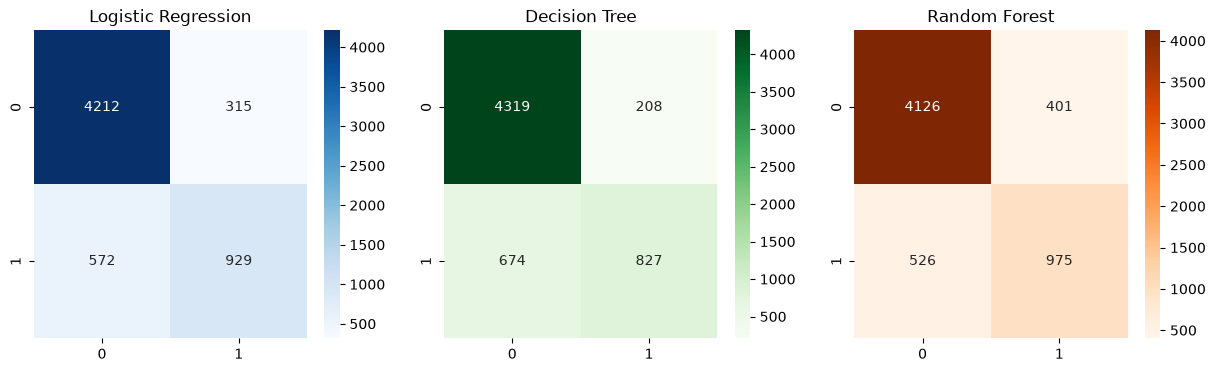

In [16]:
# ===== STEP 13: Confusion matrix ke graph (test data) =====
plt.figure(figsize=(15, 4))  # 3 graph ke liye bada figure

plt.subplot(1, 3, 1)  # pehla graph
sns.heatmap(confusion_matrix(y_te, lr_te), annot=True, fmt="d", cmap="Blues")  # LR ka matrix
plt.title("Logistic Regression")  # title

plt.subplot(1, 3, 2)  # doosra graph
sns.heatmap(confusion_matrix(y_te, dt_te), annot=True, fmt="d", cmap="Greens")  # DT ka matrix
plt.title("Decision Tree")  # title

plt.subplot(1, 3, 3)  # teesra graph
sns.heatmap(confusion_matrix(y_te, rf_te), annot=True, fmt="d", cmap="Oranges")  # RF ka matrix
plt.title("Random Forest")  # title

plt.show()  # sab graph dikhao

: Score Table + Best Model

In [17]:
# ===== STEP 14: Sab models ki tulna karo =====
res = pd.DataFrame({  # scores ki table banao
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],  # model ke naam
    "Train Acc": [accuracy_score(y_tr, lr_tr), accuracy_score(y_tr, dt_tr), accuracy_score(y_tr, rf_tr)],  # train accuracy
    "Test Acc": [accuracy_score(y_te, lr_te), accuracy_score(y_te, dt_te), accuracy_score(y_te, rf_te)],  # test accuracy
    "Precision": [precision_score(y_te, lr_te), precision_score(y_te, dt_te), precision_score(y_te, rf_te)],  # precision
    "Recall": [recall_score(y_te, lr_te), recall_score(y_te, dt_te), recall_score(y_te, rf_te)],  # recall
    "F1": [f1_score(y_te, lr_te), f1_score(y_te, dt_te), f1_score(y_te, rf_te)],  # f1 score
})
print(res.round(3))  # table dikhao

best = res.sort_values("F1", ascending=False).iloc[0]["Model"]  # sabse zyada F1 wala model
print("Best model:", best)  # winner print karo

                 Model  Train Acc  Test Acc  Precision  Recall     F1
0  Logistic Regression      0.847     0.853      0.747   0.619  0.677
1        Decision Tree      0.850     0.854      0.799   0.551  0.652
2        Random Forest      0.978     0.846      0.709   0.650  0.678
Best model: Random Forest


Feature Importance

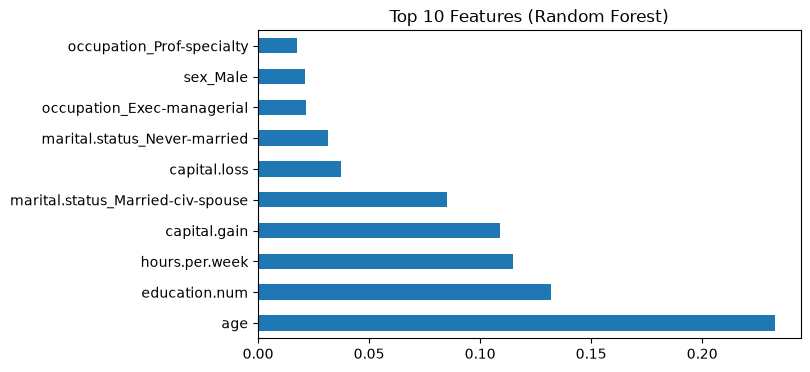

In [18]:
# ===== STEP 15: Kaun se features sabse zyada kaam ke hain =====
imp = pd.Series(rf.feature_importances_, index=X.columns)  # random forest se importance nikalo
top = imp.sort_values(ascending=False).head(10)  # top 10 lo
top.plot(kind="barh", figsize=(7, 4))  # horizontal bar graph
plt.title("Top 10 Features (Random Forest)")  # title
plt.show()  # graph dikhao

Final Conclusion

## Final Conclusion

- **Dataset:** Adult Census Income dataset. Isme humne predict kiya ki kisi insaan ki income 50K se zyada hai ya kam.
- **Pipeline:** Data Load -> Cleaning -> Encoding -> Train-Test Split -> Scaling -> 3 Models Train -> Evaluate -> Compare.
- **Models kyun use kiye:**
  - **Logistic Regression:** Simple aur fast baseline model hai, samajhna easy hai.
  - **Decision Tree:** If-else rules banata hai, isse pata chalta hai kaunsa feature kaise decide kar raha hai.
  - **Random Forest:** Bahut saare trees ek saath kaam karte hain, isliye complex patterns pakad leta hai aur ek tree se kam overfit karta hai.
- **Metrics jo use kiye:** Confusion Matrix (TP, TN, FP, FN), Accuracy, Precision, Recall aur F1 Score.
- **Sirf accuracy kyun nahi:** Data imbalanced hai (lagbhag 76% log <=50K wale hain). Model sabko "<=50K" bol de tab bhi accuracy high aayegi, isliye F1 aur Recall bhi dekhe.
- **Best model:** Step 14 ki table dekho. (Yahan apna winner model ka naam likho, jaise "Random Forest sabse best raha kyunki uska F1 sabse zyada tha".)
- **Best kyun raha:** (Yahan likho. Example: Random Forest me kai trees ka vote hota hai, isliye wo age, education, hours jaise features ke combination ko better samajhta hai.)
- **Overfitting check:** Train accuracy aur Test accuracy compare karo. Agar train bahut zyada aur test kam hai, matlab model ratta maar raha hai (overfitting).
- **Top features:** (Step 15 ke graph se top 3 features likho. Aam taur pe age, capital.gain, education.num, marital status upar aate hain.)
- **Aage kya kar sakte hain:** Hyperparameter tuning (GridSearchCV), imbalance ke liye SMOTE, aur XGBoost jaisa model try kar sakte hain.